In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split

# 한글 폰트 설정 (Windows 기준, Mac 사용 시 "AppleGothic" 등으로 변경 가능)
plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False  # 마이너스(-) 기호 깨짐 방지

In [ ]:
## M1 · 데이터 불러오기

### 생각해 볼 질문
# price의 평균과 중앙값 중 어느 쪽이 더 큰가?
# 평균(약 3,933달러)이 중앙값(약 2,401달러)보다 훨씬 크다.
# 그 차이는 가격 분포에 대해 무엇을 말해 주는가?
# 대부분의 다이아몬드는 비교적 저렴한 가격대에 몰려 있지만, 극도로 비싼 고가 다이아몬드들이 오른쪽으로 길게 늘어서며 평균을 위로 끌어올리고 있다는 뜻이다.(오른쪽으로 꼬리가 긴 분포).

In [10]:
# diamonds 데이터 불러오기
df = sns.load_dataset("diamonds")

print("데이터 크기(행, 열):", df.shape)
display(df.head())

print("\n--- 자료형 및 빈칸(결측치) 확인 ---")
df.info()

print("\n--- 숫자 열 기초 통계 ---")
display(df.describe())

데이터 크기(행, 열): (53940, 10)


,carat,cut,color,clarity,depth,table,price,x,y,z
0,0.23,Ideal,E,SI2,61.5,55.0,326,3.95,3.98,2.43
1,0.21,Premium,E,SI1,59.8,61.0,326,3.89,3.84,2.31
2,0.23,Good,E,VS1,56.9,65.0,327,4.05,4.07,2.31
3,0.29,Premium,I,VS2,62.4,58.0,334,4.20,4.23,2.63
4,0.31,Good,J,SI2,63.3,58.0,335,4.34,4.35,2.75



--- 자료형 및 빈칸(결측치) 확인 ---
<class 'pandas.DataFrame'>
RangeIndex: 53940 entries, 0 to 53939
Data columns (total 10 columns):
 #   Column   Non-Null Count  Dtype   
---  ------   --------------  -----   
 0   carat    53940 non-null  float64 
 1   cut      53940 non-null  category
 2   color    53940 non-null  category
 3   clarity  53940 non-null  category
 4   depth    53940 non-null  float64 
 5   table    53940 non-null  float64 
 6   price    53940 non-null  int64   
 7   x        53940 non-null  float64 
 8   y        53940 non-null  float64 
 9   z        53940 non-null  float64 
dtypes: category(3), float64(6), int64(1)
memory usage: 3.0 MB

--- 숫자 열 기초 통계 ---


,carat,depth,table,price,x,y,z
count,53940.000000,53940.000000,53940.000000,53940.000000,53940.000000,53940.000000,53940.000000
mean,0.797940,61.749405,57.457184,3932.799722,5.731157,5.734526,3.538734
std,0.474011,1.432621,2.234491,3989.439738,1.121761,1.142135,0.705699
min,0.200000,43.000000,43.000000,326.000000,0.000000,0.000000,0.000000
25%,0.400000,61.000000,56.000000,950.000000,4.710000,4.720000,2.910000
50%,0.700000,61.800000,57.000000,2401.000000,5.700000,5.710000,3.530000
75%,1.040000,62.500000,59.000000,5324.250000,6.540000,6.540000,4.040000
max,5.010000,79.000000,95.000000,18823.000000,10.740000,58.900000,31.800000


In [ ]:
## M2 · 이상치 정리

### 생각해 볼 질문
# 어떤 행을 왜 지웠는가?
# 1. 가로('x'), 세로('y'), 높이('z') 중 하나라도 '0'인 행(20개): 실제 다이아몬드 크기가 0mm일 수 없으므로 잘못 기록된 값이다.
# 2. 세로('y')나 높이('z')가 '20mm'를 넘는 행(3개): 다른 표본과 비교해 비정상적으로 큰 값이라 이상치로 판단해 제거했다.
# 비싼 다이아몬드는 왜 지우면 안되는가?
# 가격이 높다는 것 자체는 오류나 입력 실수가 아닌 실제로 비싸게 거래되는 '진짜 값'이기 때문이다. 진짜 데이터를 지우면 실제 시장 가격 구조를 왜곡하게 된다.

In [14]:
# 1) x, y, z 각각 0인 값 개수 세기
print("x == 0 개수:", (df["x"] == 0).sum())
print("y == 0 개수:", (df["y"] == 0).sum())
print("z == 0 개수:", (df["z"] == 0).sum())

# 2) x, y, z 중 하나라도 0인 행 개수 확인 및 조회
zero_rows = df[(df["x"] == 0) | (df["y"] == 0) | (df["z"] == 0)]
print("\nx, y, z 중 하나라도 0인 행 수:", len(zero_rows))
zero_rows

x == 0 개수: 8
y == 0 개수: 7
z == 0 개수: 20

x, y, z 중 하나라도 0인 행 수: 20


,carat,cut,color,clarity,depth,table,price,x,y,z
2207,1.00,Premium,G,SI2,59.1,59.0,3142,6.55,6.48,0.0
2314,1.01,Premium,H,I1,58.1,59.0,3167,6.66,6.60,0.0
4791,1.10,Premium,G,SI2,63.0,59.0,3696,6.50,6.47,0.0
5471,1.01,Premium,F,SI2,59.2,58.0,3837,6.50,6.47,0.0
10167,1.50,Good,G,I1,64.0,61.0,4731,7.15,7.04,0.0
11182,1.07,Ideal,F,SI2,61.6,56.0,4954,0.00,6.62,0.0
11963,1.00,Very Good,H,VS2,63.3,53.0,5139,0.00,0.00,0.0
13601,1.15,Ideal,G,VS2,59.2,56.0,5564,6.88,6.83,0.0
15951,1.14,Fair,G,VS1,57.5,67.0,6381,0.00,0.00,0.0
24394,2.18,Premium,H,SI2,59.4,61.0,12631,8.49,8.45,0.0


In [15]:
# 3) y 또는 z가 20mm를 넘는 행 조회
big_rows = df[(df["y"] > 20) | (df["z"] > 20)]
print("y 또는 z가 20mm 초과인 행 수:", len(big_rows))
big_rows

y 또는 z가 20mm 초과인 행 수: 3


,carat,cut,color,clarity,depth,table,price,x,y,z
24067,2.00,Premium,H,SI2,58.9,57.0,12210,8.09,58.90,8.06
48410,0.51,Very Good,E,VS1,61.8,54.7,1970,5.12,5.15,31.80
49189,0.51,Ideal,E,VS1,61.8,55.0,2075,5.15,31.80,5.12


In [16]:
# 4) 두 종류의 이상한 행을 모두 제외한 clean 표 만들기
clean = df[
    ~((df["x"] == 0) | (df["y"] == 0) | (df["z"] == 0) | (df["y"] > 20) | (df["z"] > 20))
].copy()

print("제거 전 행 수:", len(df))
print("제거 후 clean 행 수:", len(clean))
print("제거된 행 수:", len(df) - len(clean))

제거 전 행 수: 53940
제거 후 clean 행 수: 53917
제거된 행 수: 23


In [ ]:
## M3 · 그래프와 상관계수

### 생각해 볼 질문
# 왜 carat을 골랐는가?
# 숫자 열 중 'price'와의 상관계수가 약 '0.922'로 가장 높아, 무게('carat')가 커질수록 가격이 오르는 경향이 가장 뚜렷하기 때문이다.
# 산점도에서 직선 하나로 맞추기 어려워 보이는 부분은 어디인가?
# 무게가 커질수록 점들이 위아래로 넓게 퍼지는 구간(특히 큰 캐럿대)와, 작은 무게에서 완만하게 시작해 커지면서 살짝 위로 휘어지는 곡선 흐름 때문에 직선 하나만으로는 오차가 생긴다.

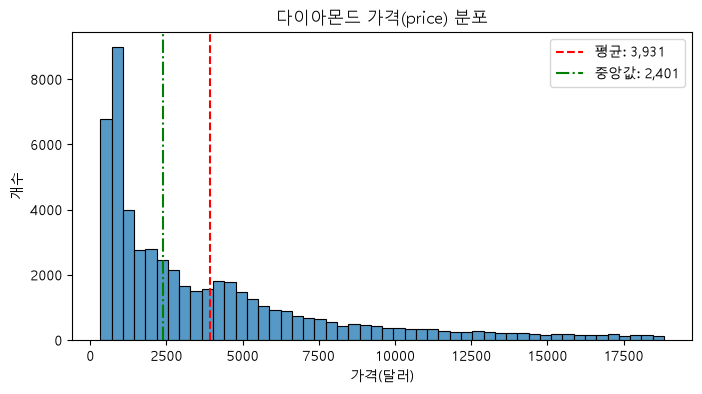

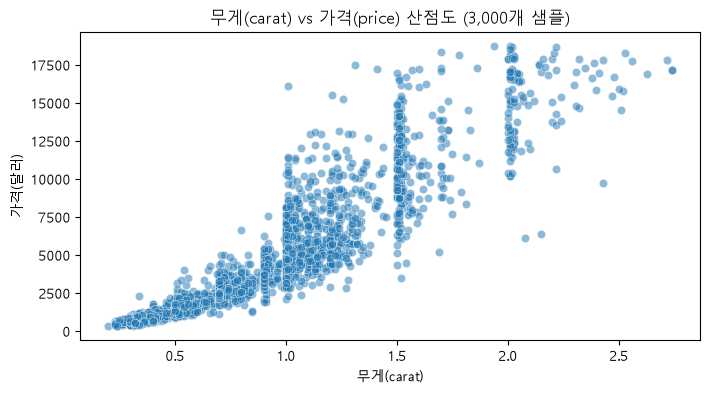

--- price와의 상관계수 순위 ---
price    1.000000
carat    0.921586
y        0.888818
x        0.887221
z        0.882107
table    0.127241
depth   -0.010653
Name: price, dtype: float64


In [21]:
# 1) price 히스토그램 + 평균/중앙값 세로선
mean_price = clean["price"].mean()
median_price = clean["price"].median()

fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(data=clean, x="price", bins=50, ax=ax)
ax.axvline(mean_price, color="red", linestyle="--", label=f"평균: {mean_price:,.0f}")
ax.axvline(median_price, color="green", linestyle="-.", label=f"중앙값: {median_price:,.0f}")
ax.set_title("다이아몬드 가격(price) 분포")
ax.set_xlabel("가격(달러)")
ax.set_ylabel("개수")
ax.legend()
plt.show()

# 2) carat과 price 산점도 (3,000개 샘플)
sample_3000 = clean.sample(3000, random_state=42)
fig, ax = plt.subplots(figsize=(8, 4))
sns.scatterplot(data=sample_3000, x="carat", y="price", alpha=0.5, ax=ax)
ax.set_title("무게(carat) vs 가격(price) 산점도 (3,000개 샘플)")
ax.set_xlabel("무게(carat)")
ax.set_ylabel("가격(달러)")
plt.show()

# 3) 숫자 열 상관계수 정렬 (price 기준 내림차순)
num_df = clean.select_dtypes("number")
corr_price = num_df.corr()["price"].sort_values(ascending=False)
print("--- price와의 상관계수 순위 ---")
print(corr_price)

In [ ]:
## M4 · 무게로 가격 예측

### 생각해 볼 질문
# 0.25캐럿 다이아몬드의 예상가가 음수인 이유는 무엇일까?
# 직선 회귀식(`y_hat = w * x + b`)에서 기울기 `w`가 약 `7,750`, 절편 `b`가 약 `-2,252`로 계산되었기 때문입니다. `0.25 * 7750 - 2252`를 계산하면 약 `-314`가 나오며, 실제 데이터에는 없는 0캐럿 근처 직선 연장선이 음수 영역으로 내려가기 때문입니다.
# 직선이 실제 점들보다 아래 · 위로 지나가는 구간은 각각 어디인가요?
# 대략 `0.4캐럿`보다 작은 구간에서는 직선이 점들 '아래'(0 달러 아래까지)로 지나가고, `0.5~1캐럿` 부근에서는 직선이 점들 '위'로 지나가는 구간이 나타난다.
# 평균 가격 가로선과 비교하면 직선은 무엇이 나아졌나?
# 평균 가격 가로선은 무게와 상관없이 항상 같은 가격만 내놓지만, 회귀직선은 무게(`carat`)가 늘수록 예측 가격도 함께 높여 주므로 실제 가격 흐름을 훨씬 잘 따라간다.

In [ ]:
# ★★★ 여기서부터 하기



# 학습용 데이터 준비 (X는 2차원 표, y는 1차원 정답)
X = clean[["carat"]]
y = clean["price"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# 선형 회귀 모델 학습
model = LinearRegression()
model.fit(X_train, y_train)

w = model.coef_[0]
b = model.intercept_
print(f"기울기(w): {w:.2f}")
print(f"절편(b): {b:.2f}")

# 0.25, 0.5, 1.0, 2.0 캐럿 예측
new_carats = pd.DataFrame({"carat": [0.25, 0.5, 1.0, 2.0]})
pred_prices = model.predict(new_carats)

for c, p in zip(new_carats["carat"], pred_prices):
    print(f"{c:.2f} 캐럿 예상가: {p:,.1f} 달러")

# 산점도(3,000개) + 회귀직선(빨강) + 평균 가격 가로선(회색)
line_x = pd.DataFrame({"carat": [0.2, 3.0]})
line_y = model.predict(line_x)
mean_train_price = y_train.mean()

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(sample_3000["carat"], sample_3000["price"], alpha=0.4, label="샘플 3,000개")
ax.plot(line_x["carat"], line_y, color="red", linewidth=2, label="선형 회귀 직선")
ax.axhline(mean_train_price, color="gray", linestyle="--", label=f"평균 가격({mean_train_price:,.0f})")
ax.set_title("carat 단일 선형 회귀 직선 vs 평균 가격")
ax.set_xlabel("무게(carat)")
ax.set_ylabel("가격(달러)")
ax.legend()
plt.show()